# SaludConex – Generación de datos sintéticos
**Notebook 1 de 2.** Genera el archivo `saludconex_reservas_2023_2025.csv`, que se carga en el notebook 2 (`02_SaludConex_Actividad_3_1_2.ipynb`).
**SCY1102 Gestión de Proyectos de Datos – Caso 2: Predicción de inasistencia a consultas médicas**

Como no se entregó un dataset, se genera uno sintético mediante **simulación basada en reglas y probabilidades**. Se distinguen los antecedentes del caso de los supuestos:

| Antecedente del caso | Implementación y supuestos explícitos |
|---|---|
| Aproximadamente tres años de historia | Se eligen 2023–2025 completos (36 meses); las fechas exactas son un supuesto. |
| Aproximadamente 32.000 atenciones realizadas al mes | Con 17% de inasistencia y 8% de cancelación supuesta sobre todas las reservas, se simulan unas 42.667 reservas mensuales: 32.000 / (1 − 0,17 − 0,08). |
| Ocho sucursales de la RM | Se representan ocho centros; nombres y distribución son supuestos. |
| Especialidades indicadas en el caso | Se incluyen las cinco mencionadas y tres adicionales como supuesto. |
| 17% de inasistencia sobre las reservas | Se calibra la probabilidad media; la tasa observada puede variar por el sorteo. |
| Diferencias entre segmentos | Se introducen efectos hipotéticos; no son hallazgos sobre pacientes reales. |
| Problemas de migración | Se inyectan nulos, formatos inconsistentes y duplicados en dos centros durante 2023. |
| Privacidad y exclusión de datos clínicos | Se utilizan personas ficticias, identificadores artificiales y datos de agendamiento. |

Para comprobar qué se sabe al predecir, se agregan marcas de tiempo operativas. El proceso se ejecuta diariamente a las **20:00 para las citas del día siguiente**, después de los recordatorios de 24 h que correspondan. Las reservas creadas después del corte quedan fuera de esa ejecución y mantienen la gestión institucional habitual. En esta simulación las cancelaciones ocurren al menos 48 h antes y sus marcas se conocen al corte; no se infiere su estado a partir del resultado futuro.

## 1. Librerías y semilla

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42                      # semilla fija -> el dataset es reproducible
rng = np.random.default_rng(SEED)
pd.set_option('display.max_columns', None)

## 2. Parámetros y supuestos
Los valores marcados con **(caso)** provienen del enunciado. El resto son **supuestos del equipo** y deben declararse en el informe.

In [2]:
# ---------- Parámetros del caso ----------
FECHA_INICIO = '2023-01-01'          # fechas elegidas por el equipo; el caso indica ~3 años
FECHA_FIN    = '2025-12-31'
ATENCIONES_MES = 32_000              # (caso) atenciones realizadas, no reservas
TASA_INASISTENCIA = 0.17             # (caso) 17% de las reservas

CENTROS = ['Providencia', 'Las Condes', 'Santiago Centro', 'Ñuñoa',
           'Maipú', 'La Florida', 'Puente Alto', 'San Bernardo']   # (caso) 8 sucursales RM; nombres = supuesto

# ---------- Supuestos del equipo ----------
N_PACIENTES = 230_000                # ~6,7 reservas por paciente en 3 años
TASA_CANCELACION = 0.08              # supuesto: proporción sobre todas las reservas
RESERVAS_MES = round(ATENCIONES_MES / (1 - TASA_INASISTENCIA - TASA_CANCELACION))
SUCURSAL_PILOTO = 'Providencia'       # elección académica: datos completos y volumen suficiente
CAPACIDAD_DIARIA = 30                # supuesto de llamadas/día; debe validarlo Operaciones
HORA_PROCESO = 20                    # corte diario a las 20:00 del día anterior
CENTROS_MIGRADOS = ['Maipú', 'San Bernardo']   # centros con registros incompletos (caso: "algunos centros")
FIN_MIGRACION = '2023-12-31'         # los problemas de calidad se concentran en 2023

# Ponderaciones territoriales ilustrativas del equipo; no representan la cartera real de SaludConex
COMUNAS = {
    'Puente Alto': 568, 'Maipú': 521, 'Santiago': 404, 'La Florida': 366, 'San Bernardo': 301,
    'Las Condes': 294, 'Peñalolén': 241, 'Pudahuel': 230, 'Quilicura': 210, 'Ñuñoa': 208,
    'La Pintana': 177, 'Estación Central': 147, 'Renca': 147, 'El Bosque': 162, 'Recoleta': 157,
    'Providencia': 142, 'Cerro Navia': 132, 'Lo Barnechea': 105, 'La Reina': 92, 'Vitacura': 85,
}
# Centro más cercano a cada comuna (el paciente se atiende ahí el 75% de las veces)
CENTRO_CERCANO = {
    'Puente Alto': 'Puente Alto', 'Maipú': 'Maipú', 'Santiago': 'Santiago Centro', 'La Florida': 'La Florida',
    'San Bernardo': 'San Bernardo', 'Las Condes': 'Las Condes', 'Peñalolén': 'La Florida', 'Pudahuel': 'Maipú',
    'Quilicura': 'Santiago Centro', 'Ñuñoa': 'Ñuñoa', 'La Pintana': 'Puente Alto', 'Estación Central': 'Santiago Centro',
    'Renca': 'Santiago Centro', 'El Bosque': 'San Bernardo', 'Recoleta': 'Santiago Centro', 'Providencia': 'Providencia',
    'Cerro Navia': 'Maipú', 'Lo Barnechea': 'Las Condes', 'La Reina': 'Ñuñoa', 'Vitacura': 'Las Condes',
}
# Grupo territorial (afecta previsión y distancia/transporte -> inasistencia)
COMUNAS_ORIENTE   = {'Las Condes', 'Vitacura', 'Lo Barnechea', 'Providencia', 'La Reina', 'Ñuñoa'}
COMUNAS_PERIFERIA = {'La Pintana', 'Cerro Navia', 'Puente Alto', 'San Bernardo', 'Renca', 'El Bosque', 'Pudahuel'}

# Especialidades: 5 del caso + 3 "otras" (supuesto). Valor = días promedio entre reserva y consulta
ESPECIALIDADES = {'Medicina general': 4, 'Pediatría': 6, 'Ginecología': 14, 'Traumatología': 15,
                  'Cardiología': 21, 'Dermatología': 18, 'Oftalmología': 16, 'Otorrinolaringología': 14}
PROFESIONALES_POR_CENTRO = {'Medicina general': 5, 'Pediatría': 2}   # el resto: 2 por centro

# Previsión (base, antes de ajustar por comuna)
PREVISIONES = ['FONASA A', 'FONASA B', 'FONASA C', 'FONASA D', 'ISAPRE', 'Particular']

# Efectos sobre el logit de inasistencia (signo + = más riesgo). Son los "verdaderos" coeficientes de la simulación.
EF_PREVISION   = {'FONASA A': 0.40, 'FONASA B': 0.30, 'FONASA C': 0.15, 'FONASA D': 0.05, 'ISAPRE': -0.20, 'Particular': -0.10}
EF_ESPECIALIDAD = {'Medicina general': 0.20, 'Pediatría': 0.00, 'Ginecología': 0.05, 'Traumatología': -0.05,
                   'Cardiología': -0.30, 'Dermatología': 0.15, 'Oftalmología': -0.05, 'Otorrinolaringología': 0.05}
EF_ZONA = {'oriente': -0.20, 'periferia': 0.25, 'otra': 0.0}
EF_CONFIRMO = -1.10            # confirmar el recordatorio reduce fuertemente el riesgo
EF_DIAS = 0.30                 # por log(1 + días de anticipación)
EF_TELEMEDICINA = 0.10
EF_LUNES = 0.10
EF_PRIMERA_HORA = 0.15         # 08:00-08:59
SD_PACIENTE = 0.80             # heterogeneidad no observada de cada paciente (hábito de asistir)

## 3. Generación de pacientes
Cada paciente tiene atributos fijos (fecha de nacimiento, comuna, previsión, centro habitual) y una **propensión latente** a no asistir que no queda en el dataset. Esa propensión es la que hace que el historial de inasistencias sea predictivo, como ocurre en la realidad.

In [3]:
ref = pd.Timestamp('2024-07-01')

# Edad a mitad del periodo según grupos etarios (supuesto)
grupos = rng.choice(5, N_PACIENTES, p=[0.18, 0.18, 0.22, 0.25, 0.17])
lim = np.array([[0, 15], [15, 30], [30, 45], [45, 65], [65, 91]])
edad_ref = rng.uniform(lim[grupos, 0], lim[grupos, 1])
nacimiento = ref - pd.to_timedelta(edad_ref * 365.25, unit='D')

com_nombres = np.array(list(COMUNAS))
com_p = np.array(list(COMUNAS.values()), dtype=float); com_p /= com_p.sum()
comuna_pac = rng.choice(com_nombres, N_PACIENTES, p=com_p)
zona_pac = np.where(np.isin(comuna_pac, list(COMUNAS_ORIENTE)), 'oriente',
           np.where(np.isin(comuna_pac, list(COMUNAS_PERIFERIA)), 'periferia', 'otra'))

# Previsión según zona (supuesto: más ISAPRE en el oriente, más FONASA A/B en la periferia)
p_prev = {'oriente':   [0.02, 0.06, 0.08, 0.14, 0.62, 0.08],
          'periferia': [0.12, 0.30, 0.20, 0.16, 0.16, 0.06],
          'otra':      [0.07, 0.20, 0.17, 0.18, 0.31, 0.07]}
prevision_pac = np.empty(N_PACIENTES, dtype=object)
for z, p in p_prev.items():
    m = zona_pac == z
    prevision_pac[m] = rng.choice(PREVISIONES, m.sum(), p=p)

centro_hab = np.array([CENTRO_CERCANO[c] for c in comuna_pac])
latente = rng.normal(0, SD_PACIENTE, N_PACIENTES)
# Frecuencia de uso: pocos pacientes concentran muchas reservas (gamma)
frecuencia = rng.gamma(0.8, 1.0, N_PACIENTES)

pacientes = pd.DataFrame({
    'id_paciente': [f'PAC-{i:06d}' for i in rng.permutation(N_PACIENTES)],
    'nacimiento': nacimiento, 'comuna': comuna_pac, 'zona': zona_pac,
    'tipo_prevision': prevision_pac, 'centro_habitual': centro_hab,
    'latente': latente, 'frecuencia': frecuencia})
pacientes.head()

,id_paciente,nacimiento,comuna,zona,tipo_prevision,centro_habitual,latente,frecuencia
0,PAC-019809,1970-03-11 01:47:27.869909116,Vitacura,oriente,FONASA A,Las Condes,-2.064483,0.916681
1,PAC-021271,1982-05-16 12:43:31.438702990,Estación Central,otra,FONASA C,Santiago Centro,-1.079180,0.679851
2,PAC-071469,1956-12-23 10:31:36.082929415,Santiago,otra,ISAPRE,Santiago Centro,0.803697,0.255431
3,PAC-127394,1968-06-14 05:54:09.786094788,Puente Alto,periferia,FONASA D,Puente Alto,0.249137,0.248511
4,PAC-113181,2016-04-05 11:01:28.558232979,Maipú,otra,FONASA C,Maipú,0.230825,0.240431


## 4. Generación de reservas (3 años)
Se distribuyen unas 42.667 reservas mensuales, con estacionalidad y menor actividad los sábados. El volumen esperado de **atenciones realizadas** es de unas 32.000 al mes. Estacionalidad, distribución y calendario operativo son supuestos, no datos observados de SaludConex.

In [4]:
dias = pd.date_range(FECHA_INICIO, FECHA_FIN, freq='D')
dias = dias[dias.dayofweek < 6]                                   # lunes a sábado
estac = {1: 0.95, 2: 0.78, 3: 1.02, 4: 1.03, 5: 1.08, 6: 1.12, 7: 1.12,
         8: 1.08, 9: 0.96, 10: 1.00, 11: 0.98, 12: 0.88}           # supuesto
peso_dia = np.where(dias.dayofweek == 5, 0.45, 1.0) * dias.month.map(estac).values

# Total de reservas = volumen mensual estimado x 36 meses; distribución diaria ponderada
n_meses = len(pd.period_range(FECHA_INICIO, FECHA_FIN, freq='M'))
N = RESERVAS_MES * n_meses
idx_dia = rng.choice(len(dias), N, p=peso_dia / peso_dia.sum())
fecha_atencion = dias[idx_dia]

# Asignar cada reserva a un paciente según su frecuencia de uso
pac_idx = rng.choice(N_PACIENTES, N, p=frecuencia / frecuencia.sum())
P = pacientes.iloc[pac_idx].reset_index(drop=True)

df = pd.DataFrame({'id_paciente': P['id_paciente'].values, 'fecha_atencion': fecha_atencion})
df['edad'] = ((df['fecha_atencion'] - P['nacimiento']).dt.days // 365.25).astype(int).clip(0, 100)
df['comuna'] = P['comuna'].values
df['tipo_prevision'] = P['tipo_prevision'].values
print(f'Reservas generadas: {N:,}  |  pacientes con al menos una reserva: {df.id_paciente.nunique():,}')

Reservas generadas: 1,536,012  |  pacientes con al menos una reserva: 191,651


### 4.1 Especialidad, centro, profesional, modalidad y horario
La especialidad depende de la edad (pediatría solo para menores de 15; ginecología desde 15 años).

In [5]:
esp_nombres = list(ESPECIALIDADES)
p_ninos  = dict(zip(esp_nombres, [0.00, 0.62, 0.00, 0.10, 0.02, 0.08, 0.08, 0.10]))
p_adulto = dict(zip(esp_nombres, [0.40, 0.00, 0.14, 0.13, 0.10, 0.08, 0.07, 0.08]))
p_mayor  = dict(zip(esp_nombres, [0.38, 0.00, 0.06, 0.15, 0.22, 0.06, 0.09, 0.04]))
especialidad = np.empty(N, dtype=object)
for mask, p in [(df.edad < 15, p_ninos), ((df.edad >= 15) & (df.edad < 65), p_adulto), (df.edad >= 65, p_mayor)]:
    especialidad[mask.values] = rng.choice(esp_nombres, mask.sum(), p=list(p.values()))
df['especialidad'] = especialidad

# Centro: 75% su centro habitual, 25% otro
otro = rng.random(N) < 0.25
df['centro_medico'] = np.where(otro, rng.choice(CENTROS, N), P['centro_habitual'].values)

# Profesional: ID anónimo por centro x especialidad
n_prof = df['especialidad'].map(lambda e: PROFESIONALES_POR_CENTRO.get(e, 2)).values
num_prof = (rng.random(N) * n_prof).astype(int) + 1
cod_centro = df['centro_medico'].map({c: i + 1 for i, c in enumerate(CENTROS)}).values
cod_esp = df['especialidad'].map({e: i + 1 for i, e in enumerate(esp_nombres)}).values
df['profesional'] = [f'PRO-{c}{e}{n:02d}' for c, e, n in zip(cod_centro, cod_esp, num_prof)]

# Modalidad: telemedicina solo en especialidades donde es viable (supuesto)
p_tele = df['especialidad'].map({'Medicina general': 0.20, 'Dermatología': 0.15, 'Cardiología': 0.10,
                                 'Pediatría': 0.08, 'Ginecología': 0.05}).fillna(0).values
df['modalidad_atencion'] = np.where(rng.random(N) < p_tele, 'Telemedicina', 'Presencial')

# Horario: bloques de 20 min, 08:00-19:40 lun-vie y 08:00-12:40 sábado
sab = df['fecha_atencion'].dt.dayofweek.values == 5
bloque = np.where(sab, rng.integers(0, 15, N), rng.integers(0, 36, N))
minutos = 8 * 60 + bloque * 20
df['horario_atencion'] = [f'{m // 60:02d}:{m % 60:02d}' for m in minutos]

# Tiempo entre reserva y consulta: exponencial con media según especialidad, máx 90 días
media_dias = df['especialidad'].map(ESPECIALIDADES).values
df['dias_anticipacion'] = np.minimum(rng.exponential(media_dias), 90).astype(int)
df['fecha_solicitud'] = df['fecha_atencion'] - pd.to_timedelta(df['dias_anticipacion'], unit='D')
df[['especialidad', 'centro_medico', 'profesional', 'modalidad_atencion', 'horario_atencion', 'dias_anticipacion']].head()
# Marcas de tiempo para reproducir un corte de información, sin usar resultados futuros.
df['fecha_hora_atencion'] = df['fecha_atencion'] + pd.to_timedelta(minutos, unit='m')
df['fecha_hora_solicitud'] = (df['fecha_hora_atencion'] - pd.to_timedelta(df['dias_anticipacion'], unit='D')
                              - pd.Timedelta(minutes=30))
df['fecha_prediccion'] = (df['fecha_atencion'] - pd.Timedelta(days=1)
                         + pd.Timedelta(hours=HORA_PROCESO))

## 5. Resultado de la reserva
Orden de la simulación:
1. Cancelación: aproximadamente 8% de todas las reservas (supuesto). Solo se simula para reservas creadas con al menos tres días de anticipación, y se registra 48 h antes de la atención.
2. Recordatorio: 24 h antes de la cita, únicamente si la reserva ya existía. Si el paciente confirma, se simula la respuesta 30 minutos después; esta no puede usarse antes de su marca de tiempo.
3. Inasistencia: sorteo logístico calibrado para aproximadamente 17% de todas las reservas. Los coeficientes son supuestos del equipo, no evidencia causal real.

In [6]:
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def calibrar(eta, objetivo):
    """Busca el intercepto b tal que mean(sigmoid(b + eta)) = objetivo (bisección)."""
    lo, hi = -15.0, 15.0
    for _ in range(60):
        b = (lo + hi) / 2
        lo, hi = (b, hi) if sigmoid(b + eta).mean() < objetivo else (lo, b)
    return b

lat = P['latente'].values
log_dias = np.log1p(df['dias_anticipacion'].values)

# 1) Cancelación
eta_c = 0.35 * log_dias + 0.3 * lat
puede_cancelar = df['dias_anticipacion'].values >= 3
objetivo_cancelacion = TASA_CANCELACION * N / puede_cancelar.sum()
b_c = calibrar(eta_c[puede_cancelar], objetivo_cancelacion)
cancelada = (rng.random(N) < sigmoid(b_c + eta_c)) & puede_cancelar
df['fecha_cancelacion'] = (df['fecha_hora_atencion'] - pd.Timedelta(hours=48)).where(cancelada)

# 2) Confirmación del recordatorio
edad = df['edad'].values
eta_conf = -0.9 * lat + np.where(edad >= 65, 0.4, 0) + np.where((edad >= 18) & (edad < 30), -0.3, 0)
recordatorio = df['fecha_hora_atencion'] - pd.Timedelta(hours=24)
reserva_existia = df['fecha_hora_solicitud'] <= recordatorio
confirmo = (rng.random(N) < sigmoid(0.6 + eta_conf)) & reserva_existia.values & ~cancelada
df['fecha_confirmacion'] = (recordatorio + pd.Timedelta(minutes=30)).where(confirmo)

# 3) Inasistencia
grupo_edad_ef = np.select([edad < 15, edad < 18, edad < 30, edad < 45, edad < 65],
                          [0.05, 0.20, 0.40, 0.15, 0.00], default=-0.25)
hora = minutos // 60
eta_n = (lat
         + grupo_edad_ef
         + df['tipo_prevision'].map(EF_PREVISION).values
         + df['especialidad'].map(EF_ESPECIALIDAD).values
         + pd.Series(P['zona'].values).map(EF_ZONA).values
         + EF_DIAS * log_dias
         + EF_CONFIRMO * confirmo
         + EF_TELEMEDICINA * (df['modalidad_atencion'].values == 'Telemedicina')
         + EF_LUNES * (df['fecha_atencion'].dt.dayofweek.values == 0)
         + EF_PRIMERA_HORA * (hora == 8))

# El 17% es sobre el total de reservas -> entre las no canceladas el objetivo es 0.17 / (1 - %canceladas)
obj_no_cancel = TASA_INASISTENCIA * N / (~cancelada).sum()
b_n = calibrar(eta_n[~cancelada], obj_no_cancel)
inasiste = (rng.random(N) < sigmoid(b_n + eta_n)) & ~cancelada

df['resultado_reserva'] = np.select([cancelada, inasiste], ['Cancelada', 'No asistió'], default='Asistió')
df['confirmacion_recordatorio'] = np.where(cancelada, 'No aplica',
                                           np.where(confirmo, 'Confirmó', 'No respondió'))
df['resultado_reserva'].value_counts(normalize=True).round(4)

resultado_reserva
Asistió       0.7502
No asistió    0.1700
Cancelada     0.0797
Name: proportion, dtype: float64

## 6. Historial del paciente
Los antecedentes se calculan con los resultados **ya conocidos al corte de predicción**, no con todas las reservas del día anterior. Una cancelación se conoce en `fecha_cancelacion`; la asistencia o inasistencia, 30 minutos después del inicio de la cita (supuesto de registro administrativo). No se utiliza el resultado de una cita posterior al corte, aunque pertenezca al mismo paciente.

In [7]:
# Construir un historial de eventos resueltos y consultarlo al corte de cada reserva.
eventos = df[['id_paciente', 'resultado_reserva', 'fecha_hora_atencion', 'fecha_cancelacion']].copy()
eventos['fecha_resultado'] = eventos['fecha_cancelacion'].fillna(
    eventos['fecha_hora_atencion'] + pd.Timedelta(minutes=30))
eventos = eventos.sort_values(['id_paciente', 'fecha_resultado']).reset_index(drop=True)
HISTORIA = {'asistencias_anteriores': 'Asistió', 'inasistencias_anteriores': 'No asistió',
            'cancelaciones_anteriores': 'Cancelada'}
for col, valor in HISTORIA.items():
    eventos[col] = eventos['resultado_reserva'].eq(valor).groupby(eventos.id_paciente).cumsum()
izq = df[['id_paciente', 'fecha_prediccion']].copy()
izq['_fila'] = np.arange(len(df))
historial = pd.merge_asof(izq.sort_values('fecha_prediccion'),
    eventos[['id_paciente', 'fecha_resultado'] + list(HISTORIA)].sort_values('fecha_resultado'),
    left_on='fecha_prediccion', right_on='fecha_resultado', by='id_paciente', direction='backward')
historial = historial.sort_values('_fila')
for col in HISTORIA:
    df[col] = historial[col].fillna(0).to_numpy(dtype=int)
assert (historial.fecha_resultado.isna() | (historial.fecha_resultado <= historial.fecha_prediccion)).all()
df[['id_paciente', 'fecha_prediccion'] + list(HISTORIA)].head(10)

,id_paciente,fecha_prediccion,asistencias_anteriores,inasistencias_anteriores,cancelaciones_anteriores
0,PAC-192207,2023-05-16 20:00:00,0,0,0
1,PAC-020590,2023-06-22 20:00:00,3,0,0
2,PAC-097684,2023-07-25 20:00:00,2,0,1
3,PAC-059565,2025-06-01 20:00:00,14,2,0
4,PAC-002535,2023-11-26 20:00:00,8,0,0
5,PAC-051054,2023-06-22 20:00:00,6,1,0
6,PAC-224676,2024-07-28 20:00:00,1,1,1
7,PAC-075045,2023-02-24 20:00:00,0,0,0
8,PAC-043811,2024-05-13 20:00:00,4,1,2
9,PAC-076313,2023-05-10 20:00:00,1,0,0


## 7. Orden final de columnas e identificador de reserva
Se conservan los campos del caso y se agrega `id_reserva`. Las cinco marcas de tiempo auxiliares permiten verificar existencia de la reserva, corte de predicción, confirmación y cancelación. Los identificadores y marcas auxiliares no se usan como predictores directos.

In [8]:
df = df.sort_values(['fecha_solicitud', 'fecha_atencion']).reset_index(drop=True)
df.insert(0, 'id_reserva', [f'RES-{i:07d}' for i in range(1, len(df) + 1)])

COLUMNAS = ['id_reserva',
            'id_paciente',                 # identificador anonimizado del paciente
            'edad',                        # edad
            'comuna',                      # comuna
            'centro_medico',               # centro médico
            'especialidad',                # especialidad
            'profesional',                 # profesional
            'fecha_solicitud',             # fecha de solicitud de la hora
            'fecha_atencion',              # fecha de atención
            'horario_atencion',            # horario de atención
            'dias_anticipacion',           # tiempo entre reserva y consulta
            'asistencias_anteriores',      # historial de asistencia
            'cancelaciones_anteriores',    # cancelaciones anteriores
            'inasistencias_anteriores',    # inasistencias anteriores
            'tipo_prevision',              # tipo de previsión
            'modalidad_atencion',          # modalidad de atención
            'confirmacion_recordatorio',   # confirmación de recordatorio
            'resultado_reserva']           # resultado final de la reserva
COLUMNAS += ['fecha_hora_atencion', 'fecha_hora_solicitud', 'fecha_prediccion',
             'fecha_cancelacion', 'fecha_confirmacion']
df = df[COLUMNAS]
df_limpio = df.copy()      # versión sin problemas de calidad (solo como referencia del equipo)
df.head()

,id_reserva,id_paciente,edad,comuna,centro_medico,especialidad,profesional,fecha_solicitud,fecha_atencion,horario_atencion,dias_anticipacion,asistencias_anteriores,cancelaciones_anteriores,inasistencias_anteriores,tipo_prevision,modalidad_atencion,confirmacion_recordatorio,resultado_reserva,fecha_hora_atencion,fecha_hora_solicitud,fecha_prediccion,fecha_cancelacion,fecha_confirmacion
0,RES-0000001,PAC-133812,27,Pudahuel,Maipú,Ginecología,PRO-5302,2022-10-04,2023-01-02,11:20,90,0,0,0,FONASA B,Presencial,Confirmó,Asistió,2023-01-02 11:20:00,2022-10-04 10:50:00,2023-01-01 20:00:00,NaT,2023-01-01 11:50:00
1,RES-0000002,PAC-031837,19,El Bosque,San Bernardo,Cardiología,PRO-8501,2022-10-05,2023-01-03,16:00,90,0,1,0,FONASA D,Presencial,No aplica,Cancelada,2023-01-03 16:00:00,2022-10-05 15:30:00,2023-01-02 20:00:00,2023-01-01 16:00:00,NaT
2,RES-0000003,PAC-211133,73,La Florida,La Florida,Cardiología,PRO-6501,2022-10-05,2023-01-03,19:40,90,0,0,0,FONASA C,Telemedicina,Confirmó,Asistió,2023-01-03 19:40:00,2022-10-05 19:10:00,2023-01-02 20:00:00,NaT,2023-01-02 20:10:00
3,RES-0000004,PAC-008776,68,Las Condes,Las Condes,Cardiología,PRO-2501,2022-10-05,2023-01-03,10:40,90,0,0,0,ISAPRE,Presencial,No respondió,Asistió,2023-01-03 10:40:00,2022-10-05 10:10:00,2023-01-02 20:00:00,NaT,NaT
4,RES-0000005,PAC-114348,8,Las Condes,Santiago Centro,Dermatología,PRO-3602,2022-10-05,2023-01-03,08:00,90,0,1,0,FONASA D,Presencial,No aplica,Cancelada,2023-01-03 08:00:00,2022-10-05 07:30:00,2023-01-02 20:00:00,2023-01-01 08:00:00,NaT


## 8. Problemas de calidad por migración
El caso indica que *"algunos centros presentan registros incompletos debido a procesos de migración desde sistemas anteriores"*. Se simula en los centros migrados durante 2023:
- valores nulos en comuna, previsión, edad y confirmación del recordatorio,
- comunas escritas con formato inconsistente (mayúsculas, sin tilde),
- un pequeño porcentaje de registros duplicados.

Esto le da trabajo real a la etapa de preparación de datos.

In [9]:
mig = df['centro_medico'].isin(CENTROS_MIGRADOS) & (df['fecha_atencion'] <= FIN_MIGRACION)
print(f'Registros afectados por la migración: {mig.sum():,}')

for col, p in [('comuna', 0.25), ('tipo_prevision', 0.18), ('edad', 0.06), ('confirmacion_recordatorio', 0.12)]:
    m = mig & (rng.random(len(df)) < p)
    df[col] = df[col].astype('object')
    df.loc[m, col] = np.nan

# Formatos inconsistentes de comuna
sin_tilde = str.maketrans('áéíóúñÁÉÍÓÚÑ', 'aeiounAEIOUN')
m = mig & df['comuna'].notna() & (rng.random(len(df)) < 0.30)
df.loc[m, 'comuna'] = df.loc[m, 'comuna'].map(lambda s: rng.choice([s.upper(), s.lower(), s.translate(sin_tilde)]))

# Duplicados (0,5% de los registros migrados)
dup = df[mig].sample(frac=0.005, random_state=SEED)
df = pd.concat([df, dup]).sort_values('id_reserva').reset_index(drop=True)
df['edad'] = df['edad'].astype('Int64')
print(f'Total final: {len(df):,} registros  |  duplicados: {df.duplicated().sum():,}')
df.isna().sum()

Registros afectados por la migración: 142,995


Total final: 1,536,727 registros  |  duplicados: 715


id_reserva                         0
id_paciente                        0
edad                            8608
comuna                         35892
centro_medico                      0
especialidad                       0
profesional                        0
fecha_solicitud                    0
fecha_atencion                     0
horario_atencion                   0
dias_anticipacion                  0
asistencias_anteriores             0
cancelaciones_anteriores           0
inasistencias_anteriores           0
tipo_prevision                 25951
modalidad_atencion                 0
confirmacion_recordatorio      17195
resultado_reserva                  0
fecha_hora_atencion                0
fecha_hora_solicitud               0
fecha_prediccion                   0
fecha_cancelacion            1414232
fecha_confirmacion            755315
dtype: int64

## 9. Validación contra el caso

In [10]:
val = df.drop_duplicates('id_reserva')
mensual = val.groupby(val.fecha_atencion.dt.to_period('M')).size()
atenciones = val[val.resultado_reserva.eq('Asistió')].groupby(val.fecha_atencion.dt.to_period('M')).size()
print('Período de atención:', val.fecha_atencion.min().date(), 'a', val.fecha_atencion.max().date())
print(f'Meses: {len(mensual)} | reservas/mes: {mensual.mean():,.0f}')
print(f'Atenciones realizadas/mes: {atenciones.mean():,.0f} (objetivo aproximado: 32.000)')
print(f'Inasistencia sobre TODAS las reservas: {val.resultado_reserva.eq("No asistió").mean():.2%}')
print(f'Cancelación sobre TODAS las reservas: {val.resultado_reserva.eq("Cancelada").mean():.2%}')
print('Centros:', val.centro_medico.nunique(), '| Especialidades:', val.especialidad.nunique())
assert ((val.fecha_atencion - val.fecha_solicitud).dt.days == val.dias_anticipacion).all()
assert val.fecha_hora_solicitud.le(val.fecha_hora_atencion).all()
print('Fechas e identificadores coherentes:', val.id_reserva.is_unique)

Período de atención: 2023-01-02 a 2025-12-31
Meses: 36 | reservas/mes: 42,667
Atenciones realizadas/mes: 32,011 (objetivo aproximado: 32.000)
Inasistencia sobre TODAS las reservas: 17.00%


Cancelación sobre TODAS las reservas: 7.97%


Centros: 8 | Especialidades: 8


Fechas e identificadores coherentes: True


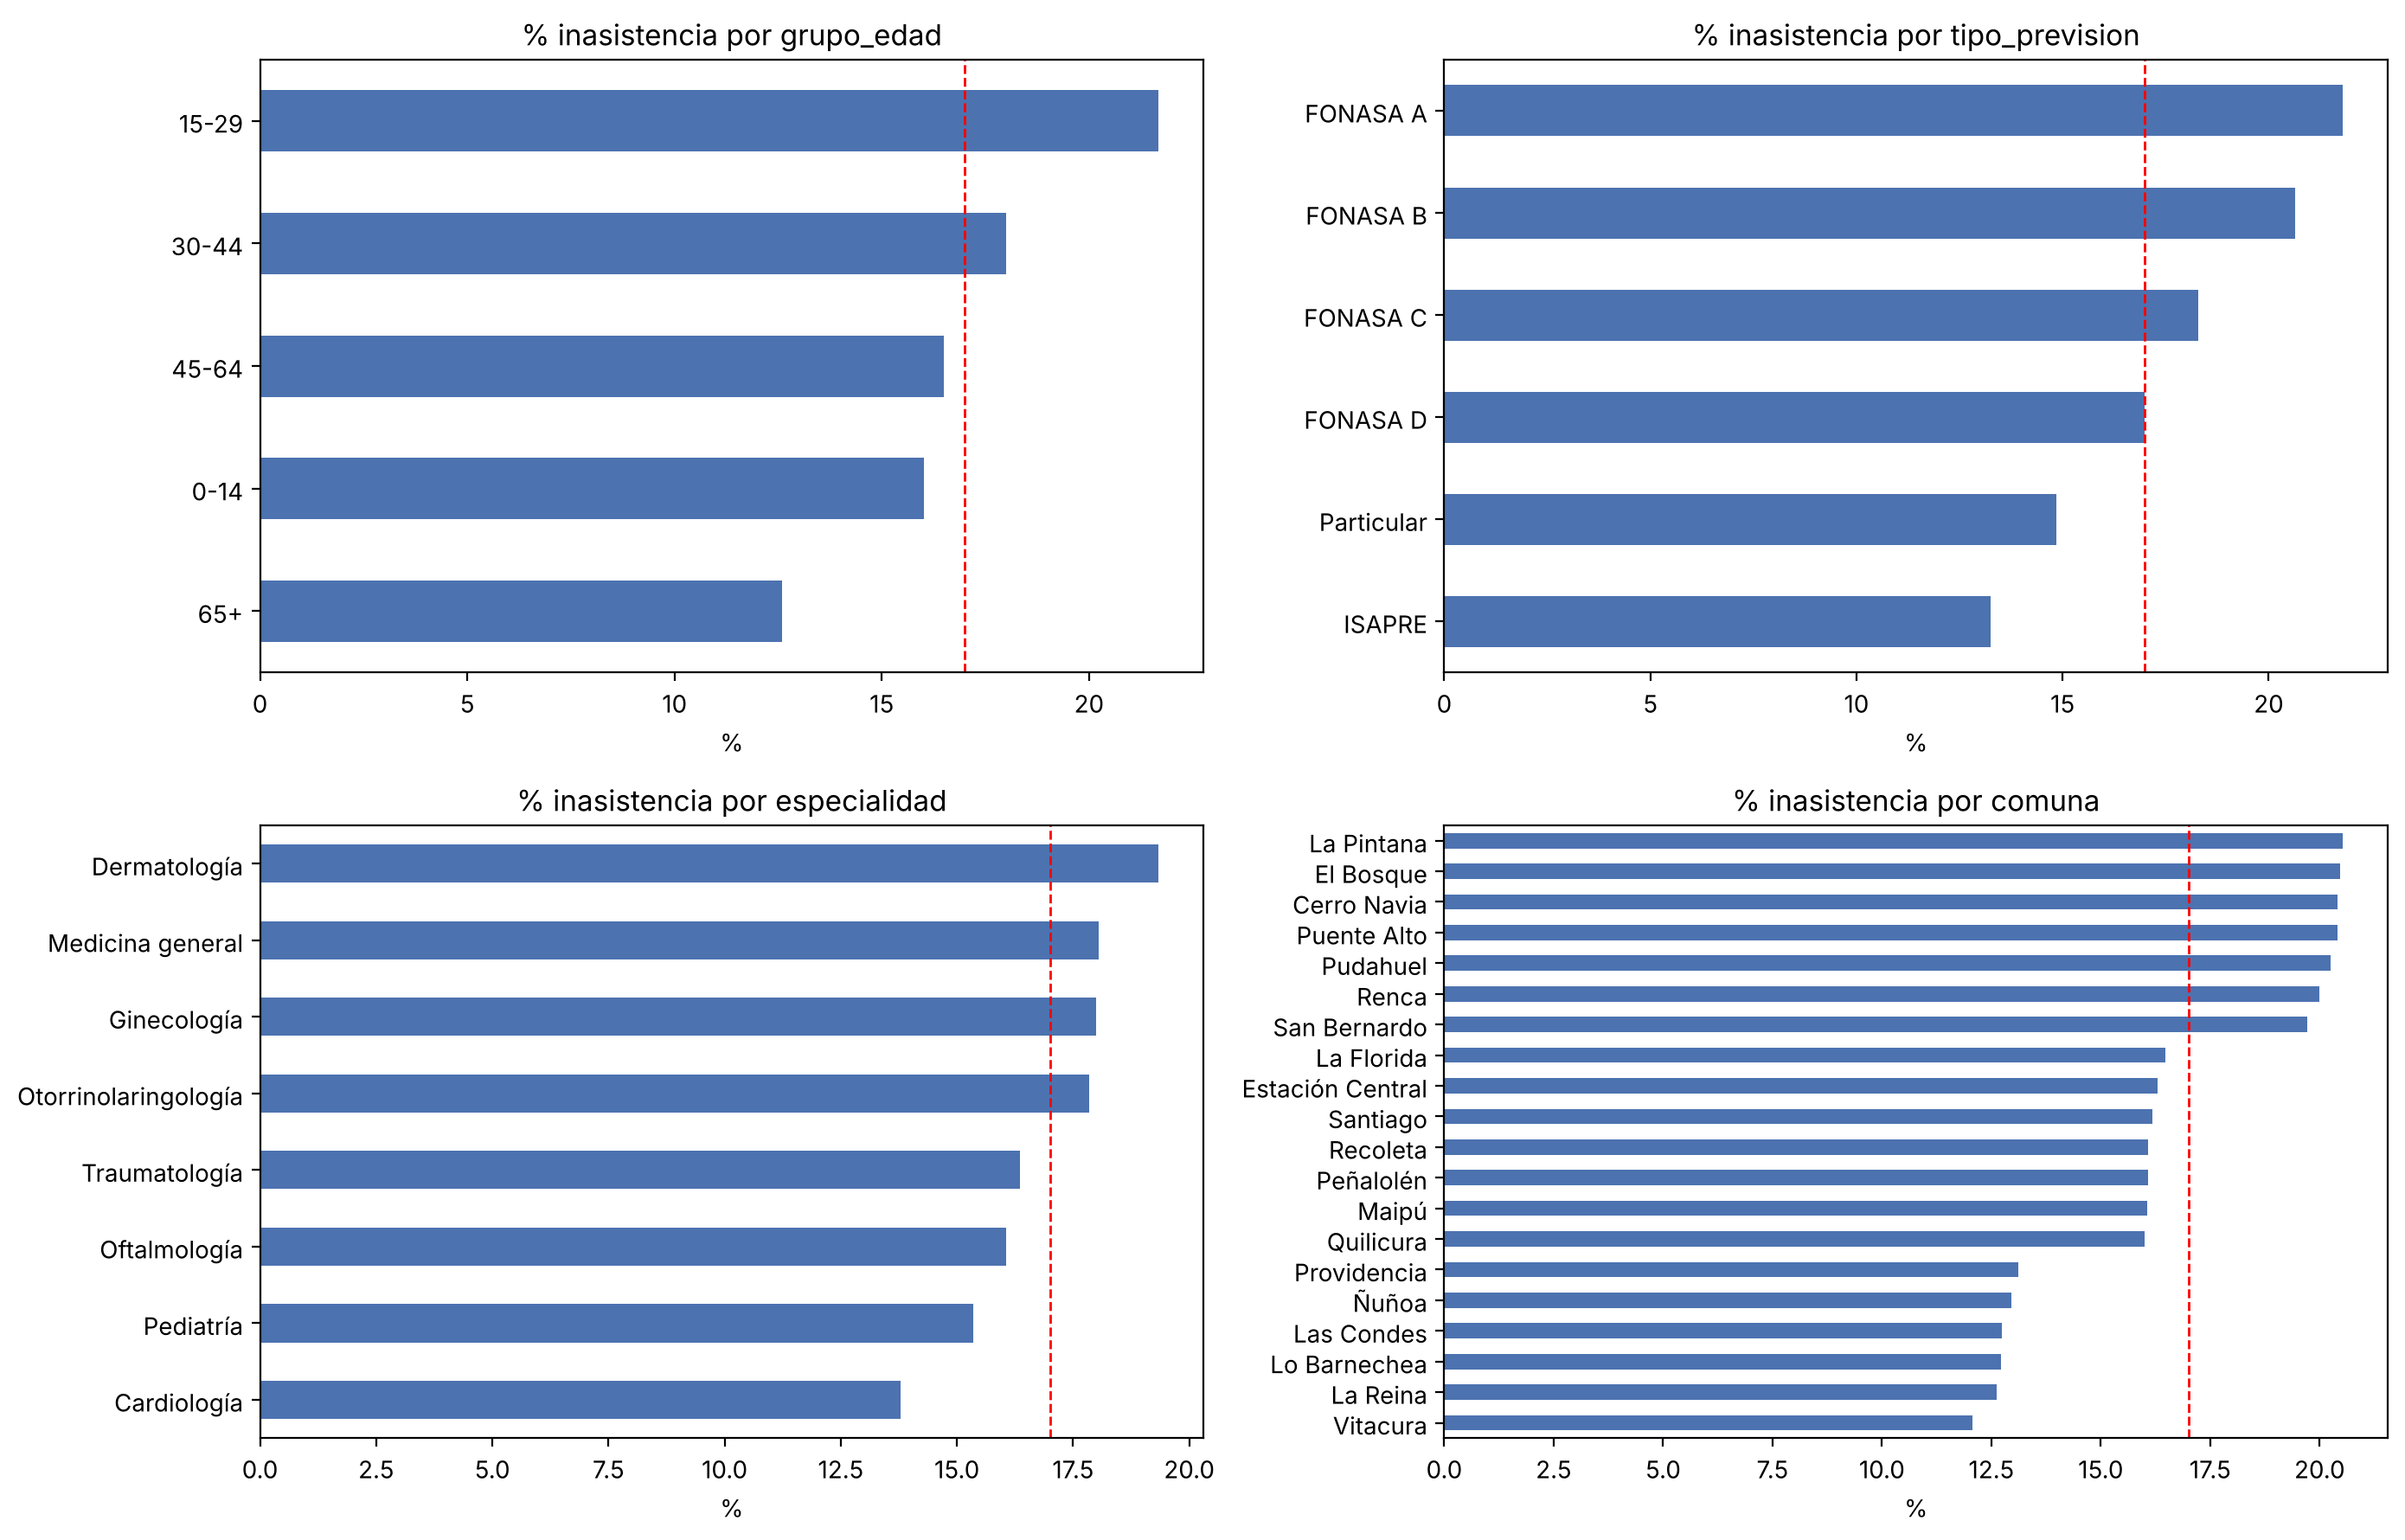

In [11]:
# El caso dice que hay diferencias de inasistencia según edad, comuna, especialidad y previsión
v = df_limpio.assign(inasistencia=(df_limpio.resultado_reserva == 'No asistió'),
                     grupo_edad=pd.cut(df_limpio.edad, [-1, 14, 29, 44, 64, 120],
                                       labels=['0-14', '15-29', '30-44', '45-64', '65+']))
fig, ax = plt.subplots(2, 2, figsize=(14, 9))
for a, col in zip(ax.flat, ['grupo_edad', 'tipo_prevision', 'especialidad', 'comuna']):
    s = v.groupby(col, observed=True)['inasistencia'].mean().sort_values() * 100
    s.plot.barh(ax=a, color='#4C72B0')
    a.axvline(17, color='red', ls='--', lw=1)
    a.set_title(f'% inasistencia por {col}'); a.set_xlabel('%'); a.set_ylabel('')
plt.tight_layout(); plt.show()

In [12]:
# El historial es predictivo: más inasistencias anteriores -> mayor tasa de inasistencia
v.groupby(v.inasistencias_anteriores.clip(upper=5))['inasistencia'].agg(['mean', 'size']).rename(
    columns={'mean': 'tasa_inasistencia', 'size': 'reservas'}).round(3)

,tasa_inasistencia,reservas
inasistencias_anteriores,,
0,0.132,782703
1,0.168,332945
2,0.201,166351
3,0.230,91396
4,0.251,55149
5,0.310,107468


## 10. Exportar el dataset
Se guarda en CSV para cargarlo en el paso 1 de la guía (y también puede abrirse en Power BI, herramienta que el caso indica que la institución ya tiene).

In [13]:
df.to_csv('saludconex_reservas_2023_2025.csv', index=False)
print('Archivo guardado:', len(df), 'filas x', df.shape[1], 'columnas')

# En Colab, para guardarlo en Google Drive (y cargarlo desde el notebook 2):
# from google.colab import drive
# drive.mount('/content/drive')
# df.to_csv('/content/drive/MyDrive/saludconex_reservas_2023_2025.csv', index=False)

Archivo guardado: 1536727 filas x 23 columnas


## Limitaciones a declarar en el informe
- Los datos y sus relaciones son sintéticos. Las métricas demuestran el procedimiento, no la efectividad clínica ni económica real.
- El caso indica 32.000 atenciones realizadas. Aquí se corrige el volumen respecto del supuesto inicial de 32.000 reservas; el análisis financiero previo deberá actualizarse con cifras institucionales.
- Las fechas 2023–2025, el 8% de cancelación, las ponderaciones territoriales, la asignación de profesionales y los efectos de cada variable son supuestos ilustrativos, no estimaciones oficiales ni resultados de un EDA real.
- Las cancelaciones se simulan al menos 48 h antes. No se modelan cancelaciones tardías; con datos reales se necesitarían estados y eventos históricos de cada reserva.
- La frecuencia de uso, las edades y los horarios son aproximaciones; no se pretende reconstruir una agenda clínica real ni validar capacidad de profesionales.
- Solo se evalúan reservas existentes al corte de las 20:00 del día anterior. Las creadas después mantienen los canales habituales.
- Se usa Gradient Boosting de scikit-learn como sustituto académico de LightGBM para reutilizar las dependencias del notebook. Debe registrarse esta adaptación respecto del plan; no se afirma haber desplegado Azure ni Power BI.
- No se incorporan fichas clínicas. Comuna y previsión se conservan solo para auditoría, fuera del modelo. La edad y el centro médico se someten a una prueba de necesidad en el notebook 2 (Paso 5.1). El historial está truncado al inicio del período: cero significa sin antecedentes observados en este dataset.
- El recordatorio se envía 24 h antes y la confirmación se registra 30 minutos después. Para las citas de las 19:40 la respuesta llega a las 20:10, después del corte de las 20:00, por lo que esas reservas nunca muestran confirmación al corte. Es un artefacto del calendario simulado, no un comportamiento de los pacientes.